In [2]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/stanfordu/stanford-question-answering-dataset/dev-v1.1.json
/kaggle/input/datasets/stanfordu/stanford-question-answering-dataset/train-v1.1.json


In [3]:
import json
import re
import string
import time
import random
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from collections import defaultdict

from transformers import (
    AutoTokenizer,
    AutoModelForQuestionAnswering,
    TrainingArguments,
    Trainer,
)

from IPython.display import display

In [4]:
SEED = 42

TRAIN_PATH = (
    "/kaggle/input/datasets/stanfordu/"
    "stanford-question-answering-dataset/"
    "train-v1.1.json"
)

DEV_PATH = (
    "/kaggle/input/datasets/stanfordu/"
    "stanford-question-answering-dataset/"
    "dev-v1.1.json"
)

MODEL_NAME = "distilbert-base-uncased"

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", DEVICE)

Device: cuda


In [5]:
def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)


set_seed(SEED)

In [6]:
# read data
def load_squad(path):
    with open(path, "r", encoding="utf-8") as f:
        data = json.load(f)

    samples = []

    for article in data["data"]:
        for paragraph in article["paragraphs"]:
            context = paragraph["context"]

            for qa in paragraph["qas"]:
                answers = qa["answers"]

                if not answers:
                    continue

                samples.append({
                    "id": qa["id"],
                    "question": qa["question"],
                    "context": context,
                    "answers": answers,
                })

    return pd.DataFrame(samples)

In [7]:
# load train and dev
train_df = load_squad(TRAIN_PATH)
dev_df = load_squad(DEV_PATH)

print("Train:", len(train_df))
print("Dev:", len(dev_df))

display(train_df.head(3))

Train: 87599
Dev: 10570


,id,question,context,answers
0,5733be284776f41900661182,To whom did the Virgin Mary allegedly appear i...,"Architecturally, the school has a Catholic cha...","[{'answer_start': 515, 'text': 'Saint Bernadet..."
1,5733be284776f4190066117f,What is in front of the Notre Dame Main Building?,"Architecturally, the school has a Catholic cha...","[{'answer_start': 188, 'text': 'a copper statu..."
2,5733be284776f41900661180,The Basilica of the Sacred heart at Notre Dame...,"Architecturally, the school has a Catholic cha...","[{'answer_start': 279, 'text': 'the Main Build..."


In [8]:
sample = train_df.iloc[0]

print("Question:")
print(sample["question"])

print("\nContext:")
print(sample["context"])

print("\nAnswers:")
print(sample["answers"])

Question:
To whom did the Virgin Mary allegedly appear in 1858 in Lourdes France?

Context:
Architecturally, the school has a Catholic character. Atop the Main Building's gold dome is a golden statue of the Virgin Mary. Immediately in front of the Main Building and facing it, is a copper statue of Christ with arms upraised with the legend "Venite Ad Me Omnes". Next to the Main Building is the Basilica of the Sacred Heart. Immediately behind the basilica is the Grotto, a Marian place of prayer and reflection. It is a replica of the grotto at Lourdes, France where the Virgin Mary reputedly appeared to Saint Bernadette Soubirous in 1858. At the end of the main drive (and in a direct line that connects through 3 statues and the Gold Dome), is a simple, modern stone statue of Mary.

Answers:
[{'answer_start': 515, 'text': 'Saint Bernadette Soubirous'}]


In [9]:
# load tokenizer
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True
)

print(tokenizer)

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

BertTokenizer(name_or_path='distilbert-base-uncased', vocab_size=30522, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	100: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	101: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	102: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	103: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})


In [10]:
question = "What is the capital of France?"
context = "The capital of France is Paris."

inputs = tokenizer(
    question,
    context,
    return_offsets_mapping=True,
)

print("Input IDs:")
print(inputs["input_ids"])

print("\nTokens:")
print(tokenizer.convert_ids_to_tokens(inputs["input_ids"]))

print("\nOffset Mapping:")
print(inputs["offset_mapping"])

Input IDs:
[101, 2054, 2003, 1996, 3007, 1997, 2605, 1029, 102, 1996, 3007, 1997, 2605, 2003, 3000, 1012, 102]

Tokens:
['[CLS]', 'what', 'is', 'the', 'capital', 'of', 'france', '?', '[SEP]', 'the', 'capital', 'of', 'france', 'is', 'paris', '.', '[SEP]']

Offset Mapping:
[(0, 0), (0, 4), (5, 7), (8, 11), (12, 19), (20, 22), (23, 29), (29, 30), (0, 0), (0, 3), (4, 11), (12, 14), (15, 21), (22, 24), (25, 30), (30, 31), (0, 0)]


In [11]:
encoding = tokenizer(
    question,
    context,
    return_offsets_mapping=True,
)

tokens = tokenizer.convert_ids_to_tokens(
    encoding["input_ids"]
)

offsets = encoding["offset_mapping"]

for i, (token, offset) in enumerate(
    zip(tokens, offsets)
):
    print(
        f"{i:3d} | {token:15s} | "
        f"{offset}"
    )

  0 | [CLS]           | (0, 0)
  1 | what            | (0, 4)
  2 | is              | (5, 7)
  3 | the             | (8, 11)
  4 | capital         | (12, 19)
  5 | of              | (20, 22)
  6 | france          | (23, 29)
  7 | ?               | (29, 30)
  8 | [SEP]           | (0, 0)
  9 | the             | (0, 3)
 10 | capital         | (4, 11)
 11 | of              | (12, 14)
 12 | france          | (15, 21)
 13 | is              | (22, 24)
 14 | paris           | (25, 30)
 15 | .               | (30, 31)
 16 | [SEP]           | (0, 0)


In [12]:
def find_token_span(offsets, answer_start, answer_end):
    start_token = None
    end_token = None

    for token_idx, (start, end) in enumerate(offsets):

        if start == end:
            continue

        if start <= answer_start < end:
            start_token = token_idx

        if start < answer_end <= end:
            end_token = token_idx

    return start_token, end_token

In [13]:
context = "The capital of France is Paris."
answer = "Paris"

answer_start = context.index(answer)
answer_end = answer_start + len(answer)

print("Context:", context)
print("Answer:", answer)

print("Character start:", answer_start)
print("Character end:", answer_end)

print(
    "Extracted:",
    context[answer_start:answer_end]
)

Context: The capital of France is Paris.
Answer: Paris
Character start: 25
Character end: 30
Extracted: Paris


In [14]:
start_token, end_token = find_token_span(
    offsets,
    answer_start,
    answer_end,
)

print("Start token:", start_token)
print("End token:", end_token)

print("Start token:", tokens[start_token])
print("End token:", tokens[end_token])

Start token: 14
End token: 14
Start token: paris
End token: paris


In [15]:
from datasets import Dataset

train_dataset = Dataset.from_pandas(
    train_df[["id", "question", "context", "answers"]],
    preserve_index=False
)

dev_dataset = Dataset.from_pandas(
    dev_df[["id", "question", "context", "answers"]],
    preserve_index=False
)

print(train_dataset)
print(dev_dataset)

Dataset({
    features: ['id', 'question', 'context', 'answers'],
    num_rows: 87599
})
Dataset({
    features: ['id', 'question', 'context', 'answers'],
    num_rows: 10570
})


In [16]:
def preprocess_qa(
    examples,
    max_length=384,
    stride=128,
):
    questions = [
        question.strip()
        for question in examples["question"]
    ]

    contexts = examples["context"]

    tokenized = tokenizer(
        questions,
        contexts,
        max_length=max_length,
        truncation="only_second",
        stride=stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False
    )


    sample_mapping = (
        tokenized["overflow_to_sample_mapping"]
    )

    offset_mapping = tokenized["offset_mapping"]

    start_positions = []
    end_positions = []
    example_ids = []
    feature_offsets = []

    for feature_idx, offsets in enumerate(
        offset_mapping
    ):
        sample_idx = sample_mapping[feature_idx]

        answer = examples["answers"][sample_idx]

        answer_text = answer[0]["text"]
        answer_start = answer[0]["answer_start"]
        
        answer_end = (
            answer_start + len(answer_text)
        )

        sequence_ids = tokenized.sequence_ids(
            feature_idx
        )

        # Chỉ lấy offset của context.
        context_token_indices = [
            i
            for i, seq_id in enumerate(sequence_ids)
            if seq_id == 1
        ]

        if not context_token_indices:
            cls_index = tokenized["input_ids"][
                feature_idx
            ].index(tokenizer.cls_token_id)

            start_positions.append(cls_index)
            end_positions.append(cls_index)

            feature_offsets.append(
                [
                    (0, 0)
                    if seq_id != 1
                    else offsets[i]
                    for i, seq_id in enumerate(
                        sequence_ids
                    )
                ]
            )

            example_ids.append(
                examples["id"][sample_idx]
            )

            continue

        context_start = context_token_indices[0]
        context_end = context_token_indices[-1]

        window_start = offsets[context_start][0]
        window_end = offsets[context_end][1]

        cls_index = tokenized["input_ids"][
            feature_idx
        ].index(tokenizer.cls_token_id)

        # Answer không nằm hoàn toàn trong window.
        if (
            answer_start < window_start
            or answer_end > window_end
        ):
            start_positions.append(cls_index)
            end_positions.append(cls_index)

        else:
            start_token = None
            end_token = None

            for token_idx in context_token_indices:

                token_start, token_end = offsets[
                    token_idx
                ]

                if (
                    token_start <= answer_start
                    < token_end
                ):
                    start_token = token_idx

                if (
                    token_start < answer_end
                    <= token_end
                ):
                    end_token = token_idx

            if (
                start_token is None
                or end_token is None
            ):
                start_positions.append(cls_index)
                end_positions.append(cls_index)

            else:
                start_positions.append(start_token)
                end_positions.append(end_token)

        # Offset của question và special tokens
        # được loại bỏ để không chọn answer ngoài context.
        cleaned_offsets = [
            offsets[i]
            if sequence_ids[i] == 1
            else (0, 0)
            for i in range(len(offsets))
        ]

        feature_offsets.append(cleaned_offsets)

        example_ids.append(
            examples["id"][sample_idx]
        )

    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions
    tokenized["example_id"] = example_ids

    tokenized["offset_mapping"] = feature_offsets

    tokenized.pop("overflow_to_sample_mapping")

    return tokenized

# 7. Experiment 1 — Context Length

In [17]:
context_lengths = [128, 256, 384]

stride_config = {
    128: 64,
    256: 128,
    384: 128
}

In [19]:
def prepare_features(dataset, max_length, stride):
    return dataset.map(
        preprocess_qa,
        batched=True,
        fn_kwargs={
            "max_length": max_length,
            "stride": stride
        },
        remove_columns=dataset.column_names
    )

In [20]:
EXP1_RATIO = 0.01

exp1_train_df = train_df.sample(
    frac=EXP1_RATIO,
    random_state=SEED,
).reset_index(drop=True)

exp1_train_dataset = Dataset.from_pandas(
    exp1_train_df[
        ["id", "question", "context", "answers"]
    ],
    preserve_index=False,
)

print("Experiment 1 train size:", len(exp1_train_dataset))

EXP1_DEV_RATIO = 0.02

exp1_dev_df = dev_df.sample(
    frac=EXP1_DEV_RATIO,
    random_state=SEED,
).reset_index(drop=True)

exp1_dev_dataset = Dataset.from_pandas(
    exp1_dev_df[
        ["id", "question", "context", "answers"]
    ],
    preserve_index=False,
)

In [21]:
train_features_128 = prepare_features(
    exp1_train_dataset,
    max_length=128,
    stride=stride_config[128]
)

dev_features_128 = prepare_features(
    exp1_dev_dataset,
    max_length=128,
    stride=stride_config[128]
)

Map:   0%|          | 0/17520 [00:00<?, ? examples/s]

Map:   0%|          | 0/10570 [00:00<?, ? examples/s]

In [22]:
def normalize_answer(text):
    text = text.lower()

    text = "".join(
        ch
        for ch in text
        if ch not in string.punctuation
    )

    text = re.sub(
        r"\b(a|an|the)\b",
        " ",
        text,
    )

    text = " ".join(text.split())

    return text


def exact_match_score(prediction, ground_truth):
    return int(
        normalize_answer(prediction)
        == normalize_answer(ground_truth)
    )


def f1_score_qa(prediction, ground_truth):
    pred_tokens = normalize_answer(
        prediction
    ).split()

    gt_tokens = normalize_answer(
        ground_truth
    ).split()

    if not pred_tokens or not gt_tokens:
        return int(
            pred_tokens == gt_tokens
        )

    common = defaultdict(int)

    for token in gt_tokens:
        common[token] += 1

    num_same = 0

    for token in pred_tokens:
        if common[token] > 0:
            num_same += 1
            common[token] -= 1

    if num_same == 0:
        return 0.0

    precision = num_same / len(pred_tokens)
    recall = num_same / len(gt_tokens)

    return (
        2 * precision * recall
        / (precision + recall)
    )

In [36]:
import re
import string
import collections


def normalize_answer(text):
    """Chuẩn hóa câu trả lời theo SQuAD."""

    def remove_articles(text):
        return re.sub(r"\b(a|an|the)\b", " ", text)

    def remove_punctuation(text):
        return "".join(
            char
            for char in text
            if char not in string.punctuation
        )

    def lower(text):
        return text.lower()

    text = lower(text)
    text = remove_punctuation(text)
    text = remove_articles(text)

    return " ".join(text.split())


def compute_exact(prediction, ground_truth):
    """Tính Exact Match."""

    return int(
        normalize_answer(prediction)
        == normalize_answer(ground_truth)
    )


def compute_f1(prediction, ground_truth):
    """Tính token-level F1 Score."""

    prediction_tokens = normalize_answer(
        prediction
    ).split()

    ground_truth_tokens = normalize_answer(
        ground_truth
    ).split()

    common = collections.Counter(
        prediction_tokens
    ) & collections.Counter(
        ground_truth_tokens
    )

    num_same = sum(common.values())

    if len(prediction_tokens) == 0 or len(ground_truth_tokens) == 0:
        return int(
            prediction_tokens == ground_truth_tokens
        )

    if num_same == 0:
        return 0.0

    precision = num_same / len(prediction_tokens)
    recall = num_same / len(ground_truth_tokens)

    return (
        2 * precision * recall
        / (precision + recall)
    )

In [37]:
def evaluate_qa(predictions, references):
    exact_matches = []
    f1_scores = []

    for prediction, reference in zip(
        predictions,
        references,
    ):
        # Hỗ trợ hai cấu trúc answers.
        if isinstance(reference, list):
            answers = [
                answer["text"]
                for answer in reference
            ]
        else:
            answers = reference["text"]

        # Tính EM và F1 với từng đáp án tham chiếu.
        em = max(
            (
                compute_exact(
                    prediction,
                    answer,
                )
                for answer in answers
            ),
            default=0.0,
        )

        f1 = max(
            (
                compute_f1(
                    prediction,
                    answer,
                )
                for answer in answers
            ),
            default=0.0,
        )

        exact_matches.append(em)
        f1_scores.append(f1)

    return {
        "EM": np.mean(exact_matches) * 100,
        "F1": np.mean(f1_scores) * 100,
    }

In [24]:
from transformers import DefaultDataCollator

data_collator = DefaultDataCollator()

In [25]:
from transformers import DataCollatorWithPadding

data_collator = DataCollatorWithPadding(
    tokenizer=tokenizer
)

In [26]:
from dataclasses import dataclass

@dataclass
class QACollator:
    tokenizer: object

    def __call__(self, features):
        start_positions = [
            feature["start_positions"]
            for feature in features
        ]

        end_positions = [
            feature["end_positions"]
            for feature in features
        ]

        features_to_pad = [
            {
                "input_ids": feature["input_ids"],
                "attention_mask": feature["attention_mask"],
            }
            for feature in features
        ]

        batch = self.tokenizer.pad(
            features_to_pad,
            padding=True,
            return_tensors="pt",
        )

        batch["start_positions"] = torch.tensor(
            start_positions,
            dtype=torch.long,
        )

        batch["end_positions"] = torch.tensor(
            end_positions,
            dtype=torch.long,
        )

        return batch

In [27]:
qa_collator = QACollator(tokenizer)

In [28]:
def create_training_args(
    output_dir,
    epochs=2,
    batch_size=16,
    learning_rate=2e-5,
):
    return TrainingArguments(
        output_dir=output_dir,

        learning_rate=learning_rate,

        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size,

        num_train_epochs=epochs,

        weight_decay=0.01,

        logging_steps=100,

        save_strategy="no",

        report_to="none",

        seed=SEED,

        fp16=torch.cuda.is_available(),
    )

In [29]:
def decode_predictions(
    model,
    features,
    raw_examples,
    max_answer_length=30,
):
    model.eval()

    predictions = {}

    # Ánh xạ ID câu hỏi với dữ liệu gốc.
    example_map = {
        row["id"]: row
        for row in raw_examples
    }

    # Chuẩn bị input cho model.
    model_inputs = []

    for feature in features:
        model_inputs.append({
            "input_ids": feature["input_ids"],
            "attention_mask": feature["attention_mask"],
        })

    # Lưu logits riêng cho từng feature.
    all_logits = []

    batch_size = 16

    for start_idx in range(
        0,
        len(model_inputs),
        batch_size,
    ):
        batch_features = model_inputs[
            start_idx:start_idx + batch_size
        ]

        # Padding các feature trong cùng batch.
        batch = tokenizer.pad(
            batch_features,
            padding=True,
            return_tensors="pt",
        )

        batch = {
            key: value.to(model.device)
            for key, value in batch.items()
        }

        with torch.no_grad():
            outputs = model(**batch)

        start_logits = outputs.start_logits.cpu().numpy()
        end_logits = outputs.end_logits.cpu().numpy()

        # Chỉ lấy phần logits tương ứng với độ dài
        # thực tế của từng feature.
        for i, feature in enumerate(batch_features):
            seq_len = len(feature["input_ids"])

            all_logits.append({
                "start": start_logits[i][:seq_len],
                "end": end_logits[i][:seq_len],
            })

    # Tìm câu trả lời tốt nhất cho từng câu hỏi.
    best_scores = {}

    for feature_idx, feature in enumerate(features):

        example_id = feature["example_id"]

        context = example_map[
            example_id
        ]["context"]

        offsets = feature["offset_mapping"]

        start_logits = all_logits[
            feature_idx
        ]["start"]

        end_logits = all_logits[
            feature_idx
        ]["end"]

        start_candidates = np.argsort(
            start_logits
        )[-20:][::-1]

        end_candidates = np.argsort(
            end_logits
        )[-20:][::-1]

        for start_idx in start_candidates:

            # Bỏ qua special tokens và padding.
            if offsets[start_idx] == (0, 0):
                continue

            for end_idx in end_candidates:

                if end_idx < start_idx:
                    continue

                answer_length = (
                    end_idx - start_idx + 1
                )

                if answer_length > max_answer_length:
                    continue

                if offsets[end_idx] == (0, 0):
                    continue

                start_char = offsets[start_idx][0]
                end_char = offsets[end_idx][1]

                if end_char <= start_char:
                    continue

                score = (
                    start_logits[start_idx]
                    + end_logits[end_idx]
                )

                answer = context[
                    start_char:end_char
                ]

                if (
                    example_id not in best_scores
                    or score > best_scores[example_id][0]
                ):
                    best_scores[example_id] = (
                        score,
                        answer,
                    )

    # Tạo prediction cho tất cả câu hỏi.
    for example_id in example_map:

        if example_id in best_scores:
            predictions[example_id] = (
                best_scores[example_id][1]
            )
        else:
            predictions[example_id] = ""

    return predictions

In [30]:
def run_experiment(
    train_features,
    dev_features,
    dev_df,
    max_length,
    epochs=2,
    batch_size=16,
    output_dir="./qa_exp",
):
    model = AutoModelForQuestionAnswering.from_pretrained(
        MODEL_NAME
    )

    args = create_training_args(
        output_dir=output_dir,
        epochs=epochs,
        batch_size=batch_size,
        learning_rate=2e-5,
    )

    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_features,
        data_collator=qa_collator,
    )

    start_time = time.time()

    trainer.train()

    training_time = (
        time.time() - start_time
    )

    predictions = decode_predictions(
        model=model,
        features=dev_features,
        raw_examples=dev_df.to_dict(
            orient="records"
        ),
    )

    prediction_list = [
        predictions[row["id"]]
        for row in dev_df.to_dict(
            orient="records"
        )
    ]

    references = [
        row["answers"]
        for row in dev_df.to_dict(
            orient="records"
        )
    ]

    metrics = evaluate_qa(
        prediction_list,
        references,
    )

    result = {
        "max_length": max_length,
        "EM": metrics["EM"],
        "F1": metrics["F1"],
        "training_time": training_time,
    }

    return result, model, trainer

In [31]:
context_lengths = [128, 256, 384]

exp1_results = []

exp1_models = {}
exp1_trainers = {}

In [32]:
EXP1_RATIO = 0.01

exp1_train_df = train_df.sample(
    frac=EXP1_RATIO,
    random_state=SEED,
).reset_index(drop=True)

exp1_train_dataset = Dataset.from_pandas(
    exp1_train_df[
        ["id", "question", "context", "answers"]
    ],
    preserve_index=False,
)

print("Experiment 1 train size:", len(exp1_train_dataset))

Experiment 1 train size: 876


In [33]:
EXP1_DEV_RATIO = 0.02

exp1_dev_df = dev_df.sample(
    frac=EXP1_DEV_RATIO,
    random_state=SEED,
).reset_index(drop=True)

exp1_dev_dataset = Dataset.from_pandas(
    exp1_dev_df[
        ["id", "question", "context", "answers"]
    ],
    preserve_index=False,
)

In [38]:
for max_length in context_lengths:
    stride = stride_config[max_length]

    print(
        f"\nExperiment: max_length={max_length}, "
        f"stride={stride}"
    )

    train_features = prepare_features(
        exp1_train_dataset,
        max_length=max_length,
        stride=stride,
    )

    dev_features = prepare_features(
        exp1_dev_dataset,
        max_length=max_length,
        stride=stride,
    )
    print("=" * 60)

    print(
        f"Experiment with max_length={max_length}"
    )

    result, model, trainer = run_experiment(
        train_features=train_features,
        dev_features=dev_features,
        dev_df=dev_df,
        max_length=max_length,
        epochs=1,
        batch_size=16,
        output_dir=(
            f"./qa_exp_{max_length}"
        ),
    )

    exp1_results.append(result)

    exp1_models[max_length] = model

    exp1_trainers[max_length] = trainer

    print(result)


Experiment: max_length=128, stride=64


Map:   0%|          | 0/876 [00:00<?, ? examples/s]

Map:   0%|          | 0/211 [00:00<?, ? examples/s]

Experiment with max_length=128


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
qa_outputs.bias         | MISSING    | 
qa_outputs.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


... (12 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
qa_outputs.bias         | MISSING    | 
qa_outputs.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Step,Training Loss


{'max_length': 384, 'EM': np.float64(0.06622516556291391), 'F1': np.float64(0.2214277304111978), 'training_time': 17.45528244972229}


In [39]:
exp1_result_df = pd.DataFrame(
    exp1_results
)

display(
    exp1_result_df.sort_values(
        "max_length"
    )
)

,max_length,EM,F1,training_time
0,128,0.075686,0.238122,16.055814
1,256,0.047304,0.202921,14.054970
2,384,0.066225,0.221428,17.455282


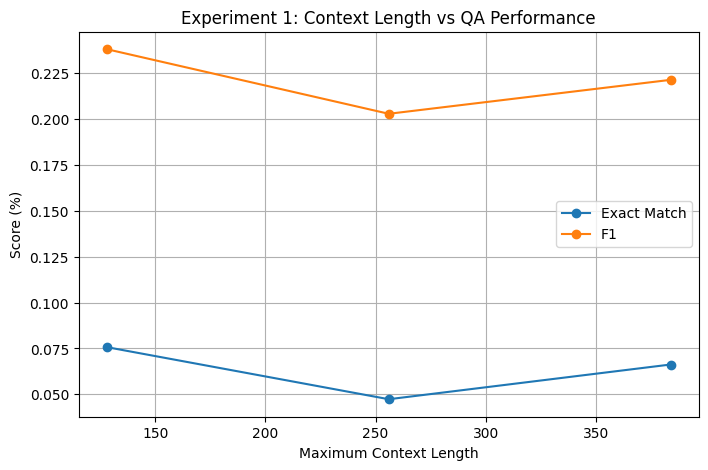

In [40]:
# visualize EM and F1
plt.figure(figsize=(8, 5))

plt.plot(
    exp1_result_df["max_length"],
    exp1_result_df["EM"],
    marker="o",
    label="Exact Match",
)

plt.plot(
    exp1_result_df["max_length"],
    exp1_result_df["F1"],
    marker="o",
    label="F1",
)

plt.xlabel("Maximum Context Length")
plt.ylabel("Score (%)")

plt.title(
    "Experiment 1: Context Length vs QA Performance"
)

plt.legend()
plt.grid(True)

plt.show()

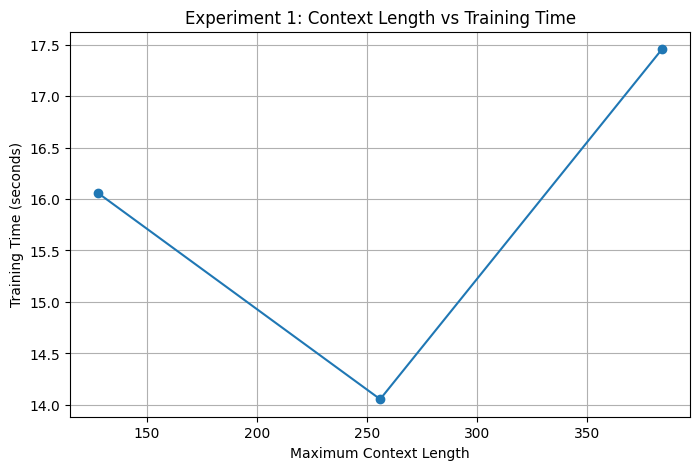

In [41]:
# visualize training time
plt.figure(figsize=(8, 5))

plt.plot(
    exp1_result_df["max_length"],
    exp1_result_df["training_time"],
    marker="o",
)

plt.xlabel("Maximum Context Length")

plt.ylabel("Training Time (seconds)")

plt.title(
    "Experiment 1: Context Length vs Training Time"
)

plt.grid(True)

plt.show()

## Trả lời câu hỏi 
### Question 1 — Tăng context length có luôn cải thiện QA không?
Khi tăng context length, model có thể tiếp cận nhiều thông tin hơn trong context. Điều này có thể giúp model tìm được answer span chính xác hơn, đặc biệt đối với các câu hỏi mà answer nằm ở vị trí xa đầu context.

Tuy nhiên, tăng context length không đảm bảo cải thiện performance vì:
- Context dài có thể chứa nhiều thông tin không liên quan.
- Model có thể bị ảnh hưởng bởi distractors.
- Answer có thể đã nằm trong context ngắn hơn.
- Sequence dài làm tăng computational cost.
- Với Transformer, attention computation có thể tăng đáng kể khi sequence length tăng.

### Question 2 — Context length ảnh hưởng tới training time như thế nào?
Khi tăng maximum sequence length:
- Số token model xử lý có thể tăng.
- GPU memory consumption có thể tăng.
- Training time có thể tăng.
Tuy nhiên, training time thực tế còn phụ thuộc vào padding, số windows, batch size, GPU và các tối ưu hóa trong framework.

### Question 3 — Context length nào phù hợp?
Bạn nên lựa chọn context length dựa trên:
- EM.
- F1.
- Training time.
- GPU memory.
- Độ ổn định của kết quả.
Không nhất thiết lựa chọn context length lớn nhất.

# 16. Experiment 2 — Fine-tuning Pretrained QA Model

In [58]:
import os
import re
import time
import string
import collections

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader

from dataclasses import dataclass

from datasets import Dataset

from transformers import (
    AutoTokenizer,
    AutoModelForQuestionAnswering,
    TrainingArguments,
    Trainer,
)

In [57]:
SEED = 42

MODEL_NAME = "distilbert-base-uncased"

MAX_LENGTH = 384
STRIDE = 128

EPOCHS = 3
BATCH_SIZE = 16

LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01

MAX_ANSWER_LENGTH = 30

OUTPUT_DIR = "./qa_experiment_2"

# 1.0: sử dụng toàn bộ dữ liệu.
# Có thể giảm xuống 0.1 để chạy thử.
TRAIN_RATIO = 1.0
DEV_RATIO = 1.0

torch.manual_seed(SEED)
np.random.seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)
print("Model:", MODEL_NAME)

Device: cuda
Model: distilbert-base-uncased


In [64]:
TRAIN_RATIO = 0.05
DEV_RATIO = 0.05sample = exp2_train_features[0]

print("Input IDs:")
print(sample["input_ids"][:20])

print("\nAttention Mask:")
print(sample["attention_mask"][:20])

print("\nStart Position:")
print(sample["start_positions"])

print("\nEnd Position:")
print(sample["end_positions"])

print("\nDecoded Answer:")
start = sample["start_positions"]
end = sample["end_positions"]

if start != end:
    answer_ids = sample["input_ids"][start:end + 1]

    print(tokenizer.decode(answer_ids))
else:
    print("Answer is not in this context window.")

In [65]:
# Lấy mẫu dữ liệu nếu cần.
exp2_train_df = train_df.sample(
    frac=TRAIN_RATIO,
    random_state=SEED,
).reset_index(drop=True)

exp2_dev_df = dev_df.sample(
    frac=DEV_RATIO,
    random_state=SEED,
).reset_index(drop=True)

# Chỉ giữ những cột cần thiết.
columns = [
    "id",
    "question",
    "context",
    "answers",
]

exp2_train_df = exp2_train_df[columns]
exp2_dev_df = exp2_dev_df[columns]

# Chuyển sang Hugging Face Dataset.
exp2_train_dataset = Dataset.from_pandas(
    exp2_train_df,
    preserve_index=False,
)

exp2_dev_dataset = Dataset.from_pandas(
    exp2_dev_df,
    preserve_index=False,
)

print("Train examples:", len(exp2_train_dataset))
print("Dev examples:", len(exp2_dev_dataset))

print("\nSample:")
print(exp2_train_dataset[0])

Train examples: 4380
Dev examples: 528

Sample:
{'id': '56de4d9ecffd8e1900b4b7e2', 'question': 'What year was the Banská Akadémia founded?', 'context': "The world's first institution of technology or technical university with tertiary technical education is the Banská Akadémia in Banská Štiavnica, Slovakia, founded in 1735, Academy since December 13, 1762 established by queen Maria Theresa in order to train specialists of silver and gold mining and metallurgy in neighbourhood. Teaching started in 1764. Later the department of Mathematics, Mechanics and Hydraulics and department of Forestry were settled. University buildings are still at their place today and are used for teaching. University has launched the first book of electrotechnics in the world.", 'answers': [{'answer_start': 167, 'text': '1735'}]}


In [66]:
tokenizer = AutoTokenizer.from_pretrained(
    MODEL_NAME,
    use_fast=True,
)

assert tokenizer.is_fast

print("Tokenizer:", MODEL_NAME)
print("CLS token:", tokenizer.cls_token)
print("SEP token:", tokenizer.sep_token)

Tokenizer: distilbert-base-uncased
CLS token: [CLS]
SEP token: [SEP]


In [67]:
def get_answers(answer):
    if isinstance(answer, dict):
        texts = answer.get("text", [])

        if isinstance(texts, str):
            return [texts]

        return list(texts)

    if isinstance(answer, list):
        return [
            item["text"]
            for item in answer
        ]

    return []

In [68]:
def find_token_span(
    offsets,
    answer_start,
    answer_end,
    cls_index,
):
    start_token = None
    end_token = None

    for token_idx, (start, end) in enumerate(offsets):

        if start == end:
            continue

        if start <= answer_start < end:
            start_token = token_idx

        if start < answer_end <= end:
            end_token = token_idx

    if start_token is None or end_token is None:
        return cls_index, cls_index

    if end_token < start_token:
        return cls_index, cls_index

    return start_token, end_token


def preprocess_qa(
    examples,
    max_length,
    stride,
):
    questions = [
        question.strip()
        for question in examples["question"]
    ]

    contexts = examples["context"]

    tokenized = tokenizer(
        questions,
        contexts,
        max_length=max_length,
        truncation="only_second",
        stride=stride,
        return_overflowing_tokens=True,
        return_offsets_mapping=True,
        padding=False,
    )

    sample_mapping = tokenized.pop(
        "overflow_to_sample_mapping"
    )

    offset_mapping = tokenized["offset_mapping"]

    start_positions = []
    end_positions = []

    example_ids = []
    processed_offsets = []

    for feature_idx, sample_idx in enumerate(
        sample_mapping
    ):
        offsets = offset_mapping[feature_idx]

        input_ids = tokenized["input_ids"][feature_idx]

        cls_index = input_ids.index(
            tokenizer.cls_token_id
        )

        answer_texts = get_answers(
            examples["answers"][sample_idx]
        )

        answer_starts_raw = examples[
            "answers"
        ][sample_idx]

        # Lấy vị trí bắt đầu của đáp án.
        if isinstance(answer_starts_raw, dict):
            answer_starts = answer_starts_raw.get(
                "answer_start",
                [],
            )
        elif isinstance(answer_starts_raw, list):
            answer_starts = [
                item["answer_start"]
                for item in answer_starts_raw
            ]
        else:
            answer_starts = []

        # Lấy đáp án đầu tiên.
        if answer_texts and answer_starts:
            answer_text = answer_texts[0]
            answer_start = answer_starts[0]

            answer_end = (
                answer_start + len(answer_text)
            )

            sequence_ids = tokenized.sequence_ids(
                feature_idx
            )

            context_positions = [
                idx
                for idx, sequence_id in enumerate(
                    sequence_ids
                )
                if sequence_id == 1
            ]

            # Xác định context window hiện tại.
            if context_positions:
                context_start = context_positions[0]
                context_end = context_positions[-1]

                window_start = offsets[
                    context_start
                ][0]

                window_end = offsets[
                    context_end
                ][1]

                # Kiểm tra đáp án có nằm trong window.
                if (
                    answer_start >= window_start
                    and answer_end <= window_end
                ):
                    start_token, end_token = find_token_span(
                        offsets,
                        answer_start,
                        answer_end,
                        cls_index,
                    )
                else:
                    start_token = cls_index
                    end_token = cls_index

            else:
                start_token = cls_index
                end_token = cls_index

        else:
            start_token = cls_index
            end_token = cls_index

        start_positions.append(start_token)
        end_positions.append(end_token)

        example_ids.append(
            examples["id"][sample_idx]
        )

        # Không cần offset của question/special tokens.
        feature_offsets = [
            offset if sequence_id == 1 else (0, 0)
            for offset, sequence_id in zip(
                offsets,
                tokenized.sequence_ids(feature_idx),
            )
        ]

        processed_offsets.append(feature_offsets)

    tokenized["start_positions"] = start_positions
    tokenized["end_positions"] = end_positions

    tokenized["example_id"] = example_ids
    tokenized["offset_mapping"] = processed_offsets

    return tokenized

In [69]:
start_time = time.time()

exp2_train_features = exp2_train_dataset.map(
    preprocess_qa,
    batched=True,
    fn_kwargs={
        "max_length": MAX_LENGTH,
        "stride": STRIDE,
    },
    remove_columns=exp2_train_dataset.column_names,
    desc="Tokenizing train dataset",
)

exp2_dev_features = exp2_dev_dataset.map(
    preprocess_qa,
    batched=True,
    fn_kwargs={
        "max_length": MAX_LENGTH,
        "stride": STRIDE,
    },
    remove_columns=exp2_dev_dataset.column_names,
    desc="Tokenizing dev dataset",
)

preprocessing_time = time.time() - start_time

print("Preprocessing time:", preprocessing_time)

print("Train features:", len(exp2_train_features))
print("Dev features:", len(exp2_dev_features))

print("\nFeature columns:")
print(exp2_train_features.column_names)

Tokenizing train dataset:   0%|          | 0/4380 [00:00<?, ? examples/s]

Tokenizing dev dataset:   0%|          | 0/528 [00:00<?, ? examples/s]

Preprocessing time: 2.5868821144104004
Train features: 4418
Dev features: 539

Feature columns:
['input_ids', 'token_type_ids', 'attention_mask', 'offset_mapping', 'start_positions', 'end_positions', 'example_id']


In [70]:
sample = exp2_train_features[0]

print("Input IDs:")
print(sample["input_ids"][:20])

print("\nAttention Mask:")
print(sample["attention_mask"][:20])

print("\nStart Position:")
print(sample["start_positions"])

print("\nEnd Position:")
print(sample["end_positions"])

print("\nDecoded Answer:")
start = sample["start_positions"]
end = sample["end_positions"]

if start != end:
    answer_ids = sample["input_ids"][start:end + 1]

    print(tokenizer.decode(answer_ids))
else:
    print("Answer is not in this context window.")

Input IDs:
[101, 2054, 2095, 2001, 1996, 7221, 8337, 9875, 3207, 10092, 2631, 1029, 102, 1996, 2088, 1005, 1055, 2034, 5145, 1997]

Attention Mask:
[1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]

Start Position:
47

End Position:
47

Decoded Answer:
Answer is not in this context window.


In [71]:
@dataclass
class QACollator:

    tokenizer: object

    def __call__(self, features):

        start_positions = [
            feature["start_positions"]
            for feature in features
        ]

        end_positions = [
            feature["end_positions"]
            for feature in features
        ]

        features_to_pad = [
            {
                "input_ids": feature["input_ids"],
                "attention_mask": feature["attention_mask"],
            }
            for feature in features
        ]

        batch = self.tokenizer.pad(
            features_to_pad,
            padding=True,
            return_tensors="pt",
        )

        batch["start_positions"] = torch.tensor(
            start_positions,
            dtype=torch.long,
        )

        batch["end_positions"] = torch.tensor(
            end_positions,
            dtype=torch.long,
        )

        return batch


qa_collator = QACollator(
    tokenizer=tokenizer,
)

In [72]:
model = AutoModelForQuestionAnswering.from_pretrained(
    MODEL_NAME,
)

model.to(device)

print("Model loaded successfully.")

print("Model parameters:",
      sum(p.numel() for p in model.parameters()))

print("Trainable parameters:",
      sum(
          p.numel()
          for p in model.parameters()
          if p.requires_grad
      ))

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForQuestionAnswering LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
qa_outputs.bias         | MISSING    | 
qa_outputs.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully.
Model parameters: 66364418
Trainable parameters: 66364418


In [73]:
training_args = TrainingArguments(
    output_dir=OUTPUT_DIR,

    num_train_epochs=EPOCHS,

    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,

    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,

    eval_strategy="epoch",
    save_strategy="epoch",

    load_best_model_at_end=True,
    metric_for_best_model="eval_loss",
    greater_is_better=False,

    logging_strategy="steps",
    logging_steps=100,

    save_total_limit=1,

    fp16=torch.cuda.is_available(),

    report_to="none",

    remove_unused_columns=False,

    seed=SEED,
)

In [74]:
trainer = Trainer(
    model=model,
    args=training_args,

    train_dataset=exp2_train_features,
    eval_dataset=exp2_dev_features,

    data_collator=qa_collator,
)

In [75]:
start_time = time.time()

train_output = trainer.train()

exp2_training_time = (
    time.time() - start_time
)

print(
    f"Training time: "
    f"{exp2_training_time:.2f} seconds"
)

print(
    "Final training loss:",
    train_output.training_loss)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss
1,4.282693,3.355512
2,3.260319,2.552921
3,2.277372,2.407023


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training time: 278.27 seconds
Final training loss: 3.0710036280057986


In [76]:
eval_results = trainer.evaluate()

exp2_validation_loss = eval_results["eval_loss"]

print("Validation Loss:", exp2_validation_loss)

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch
2.277372,2.407023,3


Validation Loss: 2.4070234298706055


In [77]:
def normalize_answer(text):

    def remove_articles(text):
        return re.sub(
            r"\b(a|an|the)\b",
            " ",
            text,
        )

    def remove_punctuation(text):
        return "".join(
            char
            for char in text
            if char not in string.punctuation
        )

    text = text.lower()
    text = remove_punctuation(text)
    text = remove_articles(text)

    return " ".join(text.split())

In [78]:
def compute_exact(prediction, ground_truth):

    return int(
        normalize_answer(prediction)
        == normalize_answer(ground_truth)
    )


def compute_f1(prediction, ground_truth):

    prediction_tokens = normalize_answer(
        prediction
    ).split()

    ground_truth_tokens = normalize_answer(
        ground_truth
    ).split()

    common = (
        collections.Counter(prediction_tokens)
        & collections.Counter(ground_truth_tokens)
    )

    num_same = sum(common.values())

    if (
        len(prediction_tokens) == 0
        or len(ground_truth_tokens) == 0
    ):
        return int(
            prediction_tokens == ground_truth_tokens
        )

    if num_same == 0:
        return 0.0

    precision = (
        num_same / len(prediction_tokens)
    )

    recall = (
        num_same / len(ground_truth_tokens)
    )

    return (
        2 * precision * recall
        / (precision + recall)
    )


def evaluate_qa(predictions, references):

    exact_matches = []
    f1_scores = []

    for prediction, reference in zip(
        predictions,
        references,
    ):

        answers = get_answers(reference)

        em = max(
            (
                compute_exact(prediction, answer)
                for answer in answers
            ),
            default=0.0,
        )

        f1 = max(
            (
                compute_f1(prediction, answer)
                for answer in answers
            ),
            default=0.0,
        )

        exact_matches.append(em)
        f1_scores.append(f1)

    return {
        "EM": np.mean(exact_matches) * 100,
        "F1": np.mean(f1_scores) * 100,
    }

In [79]:
def decode_predictions(
    model,
    features,
    raw_examples,
    max_answer_length=30,
):
    model.eval()

    example_map = {
        row["id"]: row
        for row in raw_examples
    }

    model_inputs = [
        {
            "input_ids": feature["input_ids"],
            "attention_mask": feature["attention_mask"],
        }
        for feature in features
    ]

    all_logits = []

    batch_size = 16

    for start_idx in range(
        0,
        len(model_inputs),
        batch_size,
    ):

        batch_features = model_inputs[
            start_idx:start_idx + batch_size
        ]

        batch = tokenizer.pad(
            batch_features,
            padding=True,
            return_tensors="pt",
        )

        batch = {
            key: value.to(model.device)
            for key, value in batch.items()
        }

        with torch.no_grad():
            outputs = model(**batch)

        start_logits = (
            outputs.start_logits.cpu().numpy()
        )

        end_logits = (
            outputs.end_logits.cpu().numpy()
        )

        for i, feature in enumerate(batch_features):

            seq_len = len(feature["input_ids"])

            all_logits.append({
                "start": start_logits[i][:seq_len],
                "end": end_logits[i][:seq_len],
            })

    best_scores = {}

    for feature_idx, feature in enumerate(features):

        example_id = feature["example_id"]

        context = example_map[
            example_id
        ]["context"]

        offsets = feature["offset_mapping"]

        start_logits = all_logits[
            feature_idx
        ]["start"]

        end_logits = all_logits[
            feature_idx
        ]["end"]

        start_candidates = np.argsort(
            start_logits
        )[-20:][::-1]

        end_candidates = np.argsort(
            end_logits
        )[-20:][::-1]

        for start_idx in start_candidates:

            if offsets[start_idx] == (0, 0):
                continue

            for end_idx in end_candidates:

                if end_idx < start_idx:
                    continue

                answer_length = (
                    end_idx - start_idx + 1
                )

                if answer_length > max_answer_length:
                    continue

                if offsets[end_idx] == (0, 0):
                    continue

                start_char = offsets[start_idx][0]
                end_char = offsets[end_idx][1]

                if end_char <= start_char:
                    continue

                score = (
                    start_logits[start_idx]
                    + end_logits[end_idx]
                )

                answer = context[
                    start_char:end_char
                ]

                if (
                    example_id not in best_scores
                    or score > best_scores[example_id][0]
                ):
                    best_scores[example_id] = (
                        score,
                        answer,
                    )

    predictions = {}

    for example_id in example_map:

        if example_id in best_scores:
            predictions[example_id] = (
                best_scores[example_id][1]
            )
        else:
            predictions[example_id] = ""

    return predictions

In [80]:
predictions = decode_predictions(
    model=trainer.model,
    features=exp2_dev_features,
    raw_examples=exp2_dev_df.to_dict("records"),
    max_answer_length=MAX_ANSWER_LENGTH,
)

# Đảm bảo thứ tự prediction và reference giống nhau.
prediction_list = [
    predictions[row["id"]]
    for row in exp2_dev_df.to_dict("records")
]

references = exp2_dev_df["answers"].tolist()

metrics = evaluate_qa(
    prediction_list,
    references,
)

exp2_em = metrics["EM"]
exp2_f1 = metrics["F1"]

print("Experiment 2 Results")
print("=" * 40)
print(f"EM: {exp2_em:.2f}%")
print(f"F1: {exp2_f1:.2f}%")
print(f"Training Loss: {train_output.training_loss:.4f}")
print(f"Validation Loss: {exp2_validation_loss:.4f}")

Experiment 2 Results
EM: 40.15%
F1: 51.33%
Training Loss: 3.0710
Validation Loss: 2.4070


In [81]:
for i in range(5):

    row = exp2_dev_df.iloc[i]

    print("Question:")
    print(row["question"])

    print("\nPredicted Answer:")
    print(prediction_list[i])

    print("\nGround Truth:")
    print(get_answers(row["answers"]))

    print("=" * 70)

Question:
What does increased oxygen concentrations in the patient's lungs displace?

Predicted Answer:
carbon monoxide from the heme group of hemoglobin

Ground Truth:
['carbon monoxide', 'carbon monoxide', 'carbon monoxide', 'carbon monoxide', 'carbon monoxide']
Question:
Does the new deal include Video on demand and High Definition?

Predicted Answer:
additional Video On Demand and High Definition content

Ground Truth:
['no', 'no indication', 'no indication']
Question:
In which year did Genghis Khan's grandson invade Kievan Rus'?

Predicted Answer:
1237

Ground Truth:
['1237', '1237', '1237']
Question:
Where is the Hyde Park Day School located?

Predicted Answer:
the Hyde Park Day School, a school for students with learning disabilities

Ground Truth:
['the University of Chicago campus', 'University of Chicago campus', 'the University of Chicago campus']
Question:
What does the WG I Summary for Policymakers report say human activities are doing to greenhouse gases?

Predicted Answe

In [82]:
history = trainer.state.log_history

train_losses = []
eval_losses = []

for item in history:

    if "loss" in item:
        train_losses.append({
            "step": item["step"],
            "loss": item["loss"],
        })

    if "eval_loss" in item:
        eval_losses.append({
            "step": item["step"],
            "loss": item["eval_loss"],
        })

train_loss_df = pd.DataFrame(train_losses)
eval_loss_df = pd.DataFrame(eval_losses)

print("Training loss records:")
print(train_loss_df)

print("\nValidation loss records:")
print(eval_loss_df)

Training loss records:
   step      loss
0   100  4.282693
1   200  3.260319
2   300  2.605224
3   400  2.277372

Validation loss records:
   step      loss
0   139  3.355512
1   278  2.552921
2   417  2.407023
3   417  2.407023


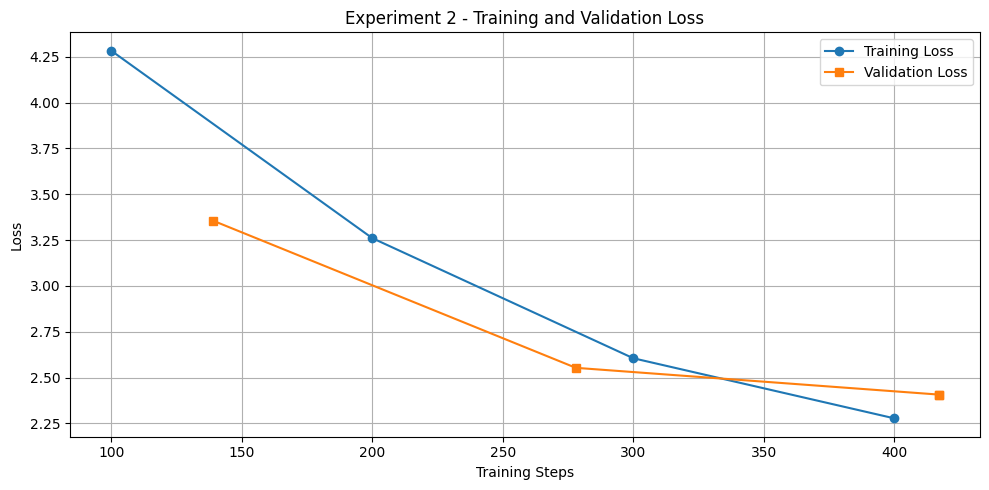

In [83]:
plt.figure(figsize=(10, 5))

if not train_loss_df.empty:
    plt.plot(
        train_loss_df["step"],
        train_loss_df["loss"],
        marker="o",
        label="Training Loss",
    )

if not eval_loss_df.empty:
    plt.plot(
        eval_loss_df["step"],
        eval_loss_df["loss"],
        marker="s",
        label="Validation Loss",
    )

plt.xlabel("Training Steps")
plt.ylabel("Loss")

plt.title(
    "Experiment 2 - Training and Validation Loss"
)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [84]:
exp2_results = {
    "Model": MODEL_NAME,
    "Max Length": MAX_LENGTH,
    "Stride": STRIDE,
    "Epochs": EPOCHS,
    "Batch Size": BATCH_SIZE,
    "Learning Rate": LEARNING_RATE,
    "Training Loss": train_output.training_loss,
    "Validation Loss": exp2_validation_loss,
    "EM": exp2_em,
    "F1": exp2_f1,
    "Training Time (s)": exp2_training_time,
    "Train Examples": len(exp2_train_dataset),
    "Dev Examples": len(exp2_dev_dataset),
}

exp2_results_df = pd.DataFrame(
    [exp2_results]
)

display(exp2_results_df)

,Model,Max Length,Stride,Epochs,Batch Size,Learning Rate,Training Loss,Validation Loss,EM,F1,Training Time (s),Train Examples,Dev Examples
0,distilbert-base-uncased,384,128,3,16,0.00002,3.071004,2.407023,40.151515,51.329744,278.266375,4380,528


# 20. Experiment 3 — EM vs F1

In [85]:
print("Number of dev examples:", len(exp2_dev_df))
print("Number of predictions:", len(prediction_list))

assert len(exp2_dev_df) == len(prediction_list)

Number of dev examples: 528
Number of predictions: 528


In [86]:
def baseline_predict(context):
    """
    Baseline: lấy câu đầu tiên trong context.
    """

    sentences = re.split(
        r"(?<=[.!?])\s+",
        context.strip(),
    )

    if not sentences:
        return ""

    return sentences[0].strip()


baseline_predictions = [
    baseline_predict(context)
    for context in exp2_dev_df["context"]
]

print("Baseline examples:")

for i in range(3):
    print("Question:")
    print(exp2_dev_df.iloc[i]["question"])

    print("\nBaseline Answer:")
    print(baseline_predictions[i])

    print("-" * 60)

Baseline examples:
Question:
What does increased oxygen concentrations in the patient's lungs displace?

Baseline Answer:
Hyperbaric (high-pressure) medicine uses special oxygen chambers to increase the partial pressure of O
2 around the patient and, when needed, the medical staff.
------------------------------------------------------------
Question:
Does the new deal include Video on demand and High Definition?

Baseline Answer:
The agreements include fixed annual carriage fees of £30m for the channels with both channel suppliers able to secure additional capped payments if their channels meet certain performance-related targets.
------------------------------------------------------------
Question:
In which year did Genghis Khan's grandson invade Kievan Rus'?

Baseline Answer:
The invasions of Baghdad, Samarkand, Urgench, Kiev, Vladimir among others caused mass murders, such as when portions of southern Khuzestan were completely destroyed.
-------------------------------------------

In [87]:
def evaluate_predictions(
    predictions,
    references,
):
    exact_matches = []
    f1_scores = []

    for prediction, reference in zip(
        predictions,
        references,
    ):
        answers = get_answers(reference)

        em = max(
            (
                compute_exact(prediction, answer)
                for answer in answers
            ),
            default=0.0,
        )

        f1 = max(
            (
                compute_f1(prediction, answer)
                for answer in answers
            ),
            default=0.0,
        )

        exact_matches.append(em)
        f1_scores.append(f1)

    return {
        "EM": np.mean(exact_matches) * 100,
        "F1": np.mean(f1_scores) * 100,
    }

In [88]:
references = exp2_dev_df["answers"].tolist()

# Đánh giá Baseline.
baseline_metrics = evaluate_predictions(
    baseline_predictions,
    references,
)

# Đánh giá Fine-tuned Transformer.
transformer_metrics = evaluate_predictions(
    prediction_list,
    references,
)

# Tổng hợp kết quả.
exp3_results = pd.DataFrame([
    {
        "Model": "Baseline",
        "EM": baseline_metrics["EM"],
        "F1": baseline_metrics["F1"],
    },
    {
        "Model": "Fine-tuned Transformer",
        "EM": transformer_metrics["EM"],
        "F1": transformer_metrics["F1"],
    },
])

display(
    exp3_results.round(2)
)

,Model,EM,F1
0,Baseline,0.00,10.34
1,Fine-tuned Transformer,40.15,51.33


In [89]:
def analyze_predictions(
    predictions,
    references,
    dataframe,
):
    records = []

    for idx, (prediction, reference) in enumerate(
        zip(predictions, references)
    ):
        answers = get_answers(reference)

        em_scores = [
            compute_exact(prediction, answer)
            for answer in answers
        ]

        f1_scores = [
            compute_f1(prediction, answer)
            for answer in answers
        ]

        best_em = max(em_scores, default=0.0)
        best_f1 = max(f1_scores, default=0.0)

        # Chọn ground truth có F1 cao nhất.
        best_answer_idx = (
            int(np.argmax(f1_scores))
            if f1_scores
            else None
        )

        ground_truth = (
            answers[best_answer_idx]
            if best_answer_idx is not None
            else ""
        )

        records.append({
            "id": dataframe.iloc[idx]["id"],
            "question": dataframe.iloc[idx]["question"],
            "context": dataframe.iloc[idx]["context"],
            "prediction": prediction,
            "ground_truth": ground_truth,
            "EM": best_em,
            "F1": best_f1,
        })

    return pd.DataFrame(records)


exp3_analysis_df = analyze_predictions(
    predictions=prediction_list,
    references=references,
    dataframe=exp2_dev_df,
)

print("Total examples:", len(exp3_analysis_df))

Total examples: 528


In [90]:
partial_match_df = exp3_analysis_df[
    (exp3_analysis_df["EM"] == 0)
    & (exp3_analysis_df["F1"] > 0)
].copy()

partial_match_df = partial_match_df.sort_values(
    by="F1",
    ascending=False,
).reset_index(drop=True)

print(
    "Number of examples with EM = 0 and F1 > 0:",
    len(partial_match_df),
)

Number of examples with EM = 0 and F1 > 0: 129


In [91]:
num_examples = min(
    5,
    len(partial_match_df),
)

for i in range(num_examples):

    row = partial_match_df.iloc[i]

    print(f"\nEXAMPLE {i + 1}")
    print("=" * 80)

    print("Question:")
    print(row["question"])

    print("\nGround Truth:")
    print(row["ground_truth"])

    print("\nPredicted Answer:")
    print(row["prediction"])

    print("\nEM:", row["EM"])
    print("F1:", round(row["F1"], 4))

    print("=" * 80)


EXAMPLE 1
Question:
What did the early entrant program do for potential students?

Ground Truth:
allowed very young students to attend college

Predicted Answer:
very young students to attend college

EM: 0
F1: 0.9231

EXAMPLE 2
Question:
What theorems are responsible for determining questions of time and space requirements?

Ground Truth:
time and space hierarchy theorems

Predicted Answer:
time and space hierarchy

EM: 0
F1: 0.8889

EXAMPLE 3
Question:
When did Kenya become an independent country?

Ground Truth:
Kenya Independence Act

Predicted Answer:
the Kenya Independence Act 1963

EM: 0
F1: 0.8571

EXAMPLE 4
Question:
Which articles state that the member states' rights to deliver public services may not be obstructed?

Ground Truth:
Articles 106 and 107

Predicted Answer:
106 and 107

EM: 0
F1: 0.8571

EXAMPLE 5
Question:
What are the biggest burdens?

Ground Truth:
diseases like malaria, HIV/AIDS, pneumonia, diarrhoea and malnutrition

Predicted Answer:
malaria, HIV/AIDS, pneu

In [92]:
examples_table = partial_match_df[
    [
        "question",
        "ground_truth",
        "prediction",
        "EM",
        "F1",
    ]
].head(5)

display(
    examples_table.round(4)
)

,question,ground_truth,prediction,EM,F1
0,What did the early entrant program do for pote...,allowed very young students to attend college,very young students to attend college,0,0.9231
1,What theorems are responsible for determining ...,time and space hierarchy theorems,time and space hierarchy,0,0.8889
2,When did Kenya become an independent country?,Kenya Independence Act,the Kenya Independence Act 1963,0,0.8571
3,Which articles state that the member states' r...,Articles 106 and 107,106 and 107,0,0.8571
4,What are the biggest burdens?,"diseases like malaria, HIV/AIDS, pneumonia, di...","malaria, HIV/AIDS, pneumonia, diarrhoea and ma...",0,0.8571


In [93]:
def classify_result(row):

    if row["EM"] == 1:
        return "Exact Match"

    if row["F1"] > 0:
        return "Partial Match"

    return "No Match"


exp3_analysis_df["Category"] = (
    exp3_analysis_df.apply(
        classify_result,
        axis=1,
    )
)

category_counts = (
    exp3_analysis_df["Category"]
    .value_counts()
    .reset_index()
)

category_counts.columns = [
    "Category",
    "Count",
]

category_counts["Percentage"] = (
    category_counts["Count"]
    / len(exp3_analysis_df)
    * 100
)

display(category_counts.round(2))

,Category,Count,Percentage
0,Exact Match,212,40.15
1,No Match,187,35.42
2,Partial Match,129,24.43


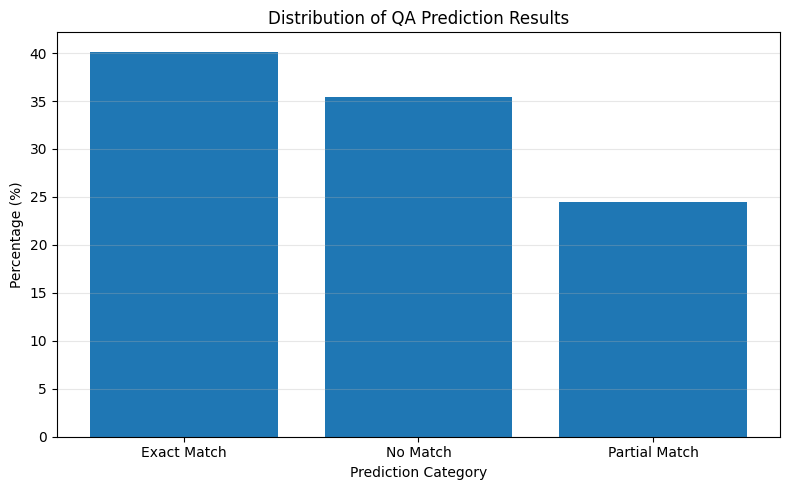

In [94]:
plt.figure(figsize=(8, 5))

plt.bar(
    category_counts["Category"],
    category_counts["Percentage"],
)

plt.ylabel("Percentage (%)")
plt.xlabel("Prediction Category")

plt.title(
    "Distribution of QA Prediction Results"
)

plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## Trả lời câu hỏi
Sự khác biệt giữa EM và F1
- Exact Match (EM): Đánh giá xem câu trả lời dự đoán có khớp hoàn toàn với đáp án chuẩn sau khi chuẩn hóa hay không. Nếu chỉ khác một từ, EM vẫn bằng 0.
- F1 Score: Đánh giá mức độ trùng khớp giữa các token của câu trả lời dự đoán và đáp án chuẩn thông qua Precision và Recall.

Kết quả thực nghiệm cho thấy EM và F1 đánh giá hai khía cạnh khác nhau của hệ thống Question Answering. EM yêu cầu câu trả lời dự đoán phải khớp hoàn toàn với đáp án tham chiếu sau khi chuẩn hóa, trong khi F1 đánh giá mức độ trùng khớp giữa các token.

Đối với những trường hợp EM = 0 nhưng F1 > 0, mô hình đã dự đoán được một phần nội dung chính xác nhưng câu trả lời vẫn chưa hoàn toàn trùng khớp với đáp án chuẩn. Nguyên nhân có thể do mô hình dự đoán thiếu token, thừa token hoặc lựa chọn một span có phạm vi rộng hoặc hẹp hơn đáp án thực tế.

EM phù hợp để đánh giá độ chính xác tuyệt đối của câu trả lời, trong khi F1 cung cấp cái nhìn mềm dẻo hơn về mức độ chính xác của nội dung dự đoán. Vì vậy, việc sử dụng đồng thời EM và F1 giúp đánh giá toàn diện hơn hiệu năng của mô hình Extractive Question Answering.

# Experiment 4

In [96]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

assert len(exp2_dev_df) == len(prediction_list)

print("Number of examples:", len(exp2_dev_df))
print("Number of predictions:", len(prediction_list))

Number of examples: 528
Number of predictions: 528


In [97]:
STOPWORDS = {
    "what", "where", "when", "who", "whom", "which",
    "why", "how", "is", "are", "was", "were",
    "the", "a", "an", "of", "in", "on", "at",
    "to", "for", "and", "or", "by", "with",
    "did", "does", "do", "has", "have", "had",
    "be", "been", "being", "it", "its",
    "that", "this", "these", "those",
    "from", "as", "into", "than", "after",
    "before", "during", "about", "over", "under"
}


def tokenize_content(text):
    words = re.findall(r"\b[a-z0-9]+\b", text.lower())

    return {
        word for word in words
        if word not in STOPWORDS
    }


def calculate_overlap(question, context):
    question_words = tokenize_content(question)
    context_words = tokenize_content(context)

    if not question_words:
        return 0.0

    common_words = question_words & context_words

    return len(common_words) / len(question_words)


def answer_not_in_question(question, answers):
    question_normalized = " ".join(
        re.findall(r"\b[a-z0-9]+\b", question.lower())
    )

    for answer in get_answers(answers):
        answer_normalized = " ".join(
            re.findall(r"\b[a-z0-9]+\b", answer.lower())
        )

        if (
            answer_normalized
            and answer_normalized in question_normalized
        ):
            return False

    return True

In [98]:
exp4_df = exp2_dev_df[
    ["id", "question", "context", "answers"]
].copy().reset_index(drop=True)

exp4_df["prediction"] = prediction_list

exp4_df["overlap_score"] = exp4_df.apply(
    lambda row: calculate_overlap(
        row["question"],
        row["context"]
    ),
    axis=1
)

exp4_df["answer_not_in_question"] = exp4_df.apply(
    lambda row: answer_not_in_question(
        row["question"],
        row["answers"]
    ),
    axis=1
)

# Chỉ giữ các câu hỏi không chứa nguyên văn đáp án.
exp4_df = exp4_df[
    exp4_df["answer_not_in_question"]
].copy()

print("Number of valid examples:", len(exp4_df))

display(
    exp4_df[
        ["question", "context", "overlap_score"]
    ].head()
)

Number of valid examples: 522


,question,context,overlap_score
0,What does increased oxygen concentrations in t...,Hyperbaric (high-pressure) medicine uses speci...,0.714286
1,Does the new deal include Video on demand and ...,The agreements include fixed annual carriage f...,1.000000
2,In which year did Genghis Khan's grandson inva...,"The invasions of Baghdad, Samarkand, Urgench, ...",0.750000
3,Where is the Hyde Park Day School located?,The university runs a number of academic insti...,0.800000
4,What does the WG I Summary for Policymakers re...,The executive summary of the WG I Summary for ...,0.818182


In [99]:
exp4_df["overlap_rank"] = exp4_df[
    "overlap_score"
].rank(method="first", pct=True)

exp4_df["group"] = np.where(
    exp4_df["overlap_rank"] <= 0.25,
    "Low Overlap",
    np.where(
        exp4_df["overlap_rank"] >= 0.75,
        "High Overlap",
        "Middle"
    )
)

# Chỉ giữ hai nhóm cần so sánh.
exp4_compare_df = exp4_df[
    exp4_df["group"].isin([
        "Low Overlap",
        "High Overlap"
    ])
].copy()

print(
    exp4_compare_df["group"].value_counts()
)

display(
    exp4_compare_df[
        ["question", "context", "overlap_score", "group"]
    ].head(10)
)

group
High Overlap    131
Low Overlap     130
Name: count, dtype: int64


,question,context,overlap_score,group
1,Does the new deal include Video on demand and ...,The agreements include fixed annual carriage f...,1.000000,High Overlap
5,For how many years was evidence shown that hum...,The first European to travel the length of the...,0.571429,Low Overlap
7,Who was hired to be the deputy director of the...,Seamans' establishment of an ad-hoc committee...,1.000000,High Overlap
8,What register did Chris Keates think that some...,"Chris Keates, the general secretary of Nationa...",0.888889,High Overlap
9,What did Luther say would allow the Jews to stay?,"His last sermon was delivered at Eisleben, his...",0.500000,Low Overlap
11,Where was the 1857 riot?,Immigrants arrived from all over the world to ...,1.000000,High Overlap
13,How did Chinese medicine spread?,The Chinese medical tradition of the Yuan had ...,1.000000,High Overlap
15,The point at which different radiometric isoto...,"For many geologic applications, isotope ratios...",0.900000,High Overlap
19,Civil Disobedience is mainly performed by what...,Civil disobedience is usually defined as perta...,0.333333,Low Overlap
20,Who was the executive producer of the 2005 Doc...,"With the show's 2005 revival, executive produc...",1.000000,High Overlap


In [100]:
print("HIGH LEXICAL OVERLAP")
display(
    exp4_compare_df[
        exp4_compare_df["group"] == "High Overlap"
    ][
        ["question", "context", "overlap_score"]
    ].head(5)
)

print("LOW LEXICAL OVERLAP")
display(
    exp4_compare_df[
        exp4_compare_df["group"] == "Low Overlap"
    ][
        ["question", "context", "overlap_score"]
    ].head(5)
)

HIGH LEXICAL OVERLAP


,question,context,overlap_score
1,Does the new deal include Video on demand and ...,The agreements include fixed annual carriage f...,1.000000
7,Who was hired to be the deputy director of the...,Seamans' establishment of an ad-hoc committee...,1.000000
8,What register did Chris Keates think that some...,"Chris Keates, the general secretary of Nationa...",0.888889
11,Where was the 1857 riot?,Immigrants arrived from all over the world to ...,1.000000
13,How did Chinese medicine spread?,The Chinese medical tradition of the Yuan had ...,1.000000


LOW LEXICAL OVERLAP


,question,context,overlap_score
5,For how many years was evidence shown that hum...,The first European to travel the length of the...,0.571429
9,What did Luther say would allow the Jews to stay?,"His last sermon was delivered at Eisleben, his...",0.500000
19,Civil Disobedience is mainly performed by what...,Civil disobedience is usually defined as perta...,0.333333
21,An MSP may introduce a bill as what?,Bills can be introduced to Parliament in a num...,0.500000
29,What team did the Panthers defeat?,The Panthers finished the regular season with ...,0.333333


In [101]:
def calculate_example_metrics(prediction, answers):
    references = get_answers(answers)

    if not references:
        return 0.0, 0.0

    exact_scores = [
        compute_exact(prediction, answer)
        for answer in references
    ]

    f1_scores = [
        compute_f1(prediction, answer)
        for answer in references
    ]

    return max(exact_scores), max(f1_scores)


metrics = exp4_compare_df.apply(
    lambda row: calculate_example_metrics(
        row["prediction"],
        row["answers"]
    ),
    axis=1
)

exp4_compare_df["EM"] = [
    item[0] for item in metrics
]

exp4_compare_df["F1"] = [
    item[1] for item in metrics
]

display(
    exp4_compare_df[
        [
            "question",
            "prediction",
            "EM",
            "F1",
            "overlap_score",
            "group"
        ]
    ].head()
)

,question,prediction,EM,F1,overlap_score,group
1,Does the new deal include Video on demand and ...,additional Video On Demand and High Definition...,0,0.0,1.000000,High Overlap
5,For how many years was evidence shown that hum...,"11,000 years",1,1.0,0.571429,Low Overlap
7,Who was hired to be the deputy director of the...,Joseph Shea,1,1.0,1.000000,High Overlap
8,What register did Chris Keates think that some...,sex offenders register,1,1.0,0.888889,High Overlap
9,What did Luther say would allow the Jews to stay?,Eisleben,0,0.0,0.500000,Low Overlap


In [102]:
exp4_results = (
    exp4_compare_df
    .groupby("group")
    .agg(
        Num_Examples=("id", "count"),
        Avg_Overlap=("overlap_score", "mean"),
        EM=("EM", "mean"),
        F1=("F1", "mean")
    )
    .reset_index()
)

exp4_results["EM"] *= 100
exp4_results["F1"] *= 100

exp4_results["EM"] = exp4_results["EM"].round(2)
exp4_results["F1"] = exp4_results["F1"].round(2)
exp4_results["Avg_Overlap"] = (
    exp4_results["Avg_Overlap"].round(4)
)

display(exp4_results)

,group,Num_Examples,Avg_Overlap,EM,F1
0,High Overlap,131,0.9494,45.8,56.22
1,Low Overlap,130,0.4250,30.0,41.38


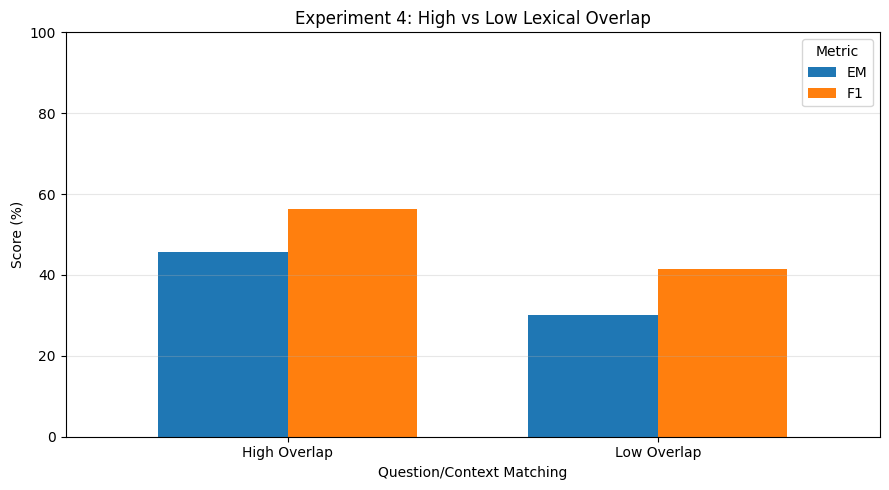

In [103]:
plot_df = exp4_results.set_index("group")[["EM", "F1"]]

plot_df.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Experiment 4: High vs Low Lexical Overlap")
plt.xlabel("Question/Context Matching")
plt.ylabel("Score (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

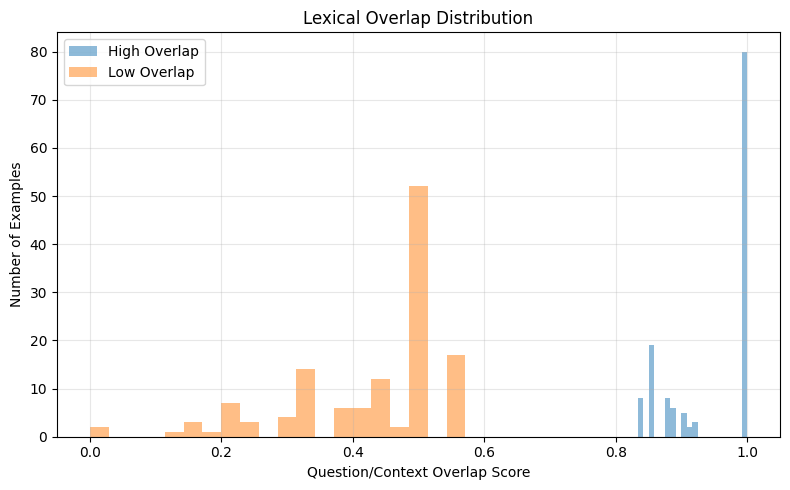

In [104]:
plt.figure(figsize=(8, 5))

for group in ["High Overlap", "Low Overlap"]:
    scores = exp4_compare_df.loc[
        exp4_compare_df["group"] == group,
        "overlap_score"
    ]

    plt.hist(
        scores,
        bins=20,
        alpha=0.5,
        label=group
    )

plt.title("Lexical Overlap Distribution")
plt.xlabel("Question/Context Overlap Score")
plt.ylabel("Number of Examples")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [105]:
low_overlap_correct = exp4_compare_df[
    (exp4_compare_df["group"] == "Low Overlap")
    & (exp4_compare_df["EM"] == 1)
]

display(
    low_overlap_correct[
        [
            "question",
            "context",
            "prediction",
            "overlap_score"
        ]
    ].head(10)
)

,question,context,prediction,overlap_score
5,For how many years was evidence shown that hum...,The first European to travel the length of the...,"11,000 years",0.571429
21,An MSP may introduce a bill as what?,Bills can be introduced to Parliament in a num...,private member,0.500000
29,What team did the Panthers defeat?,The Panthers finished the regular season with ...,Arizona Cardinals,0.333333
40,What had the number of people living in Warsaw...,"In 1939, c. 1,300,000 people lived in Warsaw, ...","420,000",0.500000
43,How many soldiers did Genghis Khan take with h...,"In the early 13th century, the Khwarazmian dyn...","100,000",0.571429
65,What is the term for closing off rivers that a...,The hydrography of the current delta is charac...,dammed,0.142857
73,What service did Verizon customers need to use...,CBS provided digital streams of the game via C...,NFL Mobile,0.555556
78,Approximately how many architectural drawings ...,"In 2004, the V&A alongside Royal Institute of ...","600,000",0.571429
85,What's the climate like in Newcastle?,The climate in Newcastle is oceanic (Köppen Cf...,oceanic,0.500000
89,What kind of programs can be credited for ABC'...,It was not until the late 1950s that the ABC n...,westerns and detective series,0.444444


In [106]:
low_overlap_wrong = exp4_compare_df[
    (exp4_compare_df["group"] == "Low Overlap")
    & (exp4_compare_df["EM"] == 0)
]

display(
    low_overlap_wrong[
        [
            "question",
            "context",
            "prediction",
            "answers",
            "overlap_score",
            "F1"
        ]
    ].head(10)
)

,question,context,prediction,answers,overlap_score,F1
9,What did Luther say would allow the Jews to stay?,"His last sermon was delivered at Eisleben, his...",Eisleben,"[{'answer_start': 528, 'text': 'that they conv...",0.500000,0.000000
19,Civil Disobedience is mainly performed by what...,Civil disobedience is usually defined as perta...,her or his capacity as public official,"[{'answer_start': 505, 'text': 'private citize...",0.333333,0.000000
37,"What was Isiah Bowman nick name, as known by t...",One key figure in the plans for what would com...,geographer,"[{'answer_start': 623, 'text': 'Wilson's geogr...",0.500000,0.666667
46,What was the English name of Gou's calendar?,Guo Shoujing applied mathematics to the constr...,the Shoushi Li,"[{'answer_start': 265, 'text': 'Calendar for F...",0.400000,0.000000
51,What shape are pyrenoids?,The chloroplasts of some hornworts and algae c...,CO2,"[{'answer_start': 133, 'text': 'roughly spheri...",0.500000,0.000000
58,The Ottoman empire controlled territory on thr...,The Ottoman Empire was an imperial state that ...,"Southeast Europe, Western Asia, the Caucasus, ...","[{'answer_start': 293, 'text': 'Europe'}, {'an...",0.444444,0.166667
66,How many of Jacksonville's city residents are ...,"As of 2010[update], there were 366,273 househo...","366,273","[{'answer_start': 508, 'text': '23.9%'}, {'ans...",0.285714,0.000000
84,How did Luther's writings sound as he became l...,His poor physical health made him short-temper...,short-tempered,"[{'answer_start': 58, 'text': 'harsher'}, {'an...",0.375000,0.000000
86,What is the most feared condition that divers ...,Oxygen toxicity to the lungs and central nervo...,Acute oxygen toxicity (causing seizures,"[{'answer_start': 384, 'text': 'Acute oxygen t...",0.500000,0.750000
87,Other theories of the word's origin can be gen...,Some disagree with such double or triple non-F...,French language,"[{'answer_start': 24, 'text': 'double or tripl...",0.375000,0.000000


## Nhận xét kết quả:

Dựa trên kết quả thực nghiệm, so sánh EM và F1 giữa hai nhóm cho phép đánh giá ảnh hưởng của mức độ trùng khớp từ vựng đến hiệu năng Question Answering.

Nếu nhóm High Overlap đạt kết quả cao hơn nhóm Low Overlap, điều này cho thấy mô hình có xu hướng tận dụng sự tương đồng về từ vựng giữa câu hỏi và context để xác định câu trả lời.

Ngược lại, nếu kết quả giữa hai nhóm không có sự chênh lệch đáng kể, mô hình có thể khai thác thêm thông tin ngữ cảnh và biểu diễn ngữ nghĩa thay vì chỉ dựa vào sự xuất hiện của các từ giống nhau.

## Kết luận:

Lexical Overlap là một yếu tố có thể ảnh hưởng đến hiệu năng của hệ thống Extractive Question Answering. Việc đánh giá trên cả hai nhóm giúp kiểm tra khả năng xử lý các câu hỏi có cách diễn đạt khác với context của mô hình.

Một hệ thống Question Answering tốt không chỉ cần nhận diện những từ xuất hiện đồng thời trong câu hỏi và context mà còn cần khai thác được thông tin ngữ nghĩa để xác định chính xác đoạn văn bản chứa đáp án.

# Experiment 5

In [107]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


def count_answer_tokens(answer):
    """Đếm số từ trong đáp án, bỏ qua dấu câu."""
    return len(
        re.findall(r"\b[a-zA-Z0-9]+\b", answer)
    )


def get_length_group(token_count):
    if token_count == 1:
        return "1 token"
    elif 2 <= token_count <= 3:
        return "2-3 tokens"
    elif 4 <= token_count <= 6:
        return "4-6 tokens"
    else:
        return "7+ tokens"

In [108]:
exp5_df = exp2_dev_df[
    ["id", "question", "context", "answers"]
].copy().reset_index(drop=True)

exp5_df["prediction"] = prediction_list

# Lấy đáp án tham chiếu đầu tiên để phân nhóm.
exp5_df["reference_answers"] = exp5_df["answers"].apply(
    get_answers
)

# Loại những ví dụ không có đáp án tham chiếu.
exp5_df = exp5_df[
    exp5_df["reference_answers"].apply(len) > 0
].copy()

exp5_df["reference_answer"] = exp5_df[
    "reference_answers"
].apply(lambda answers: answers[0])

# Tính độ dài đáp án.
exp5_df["answer_length"] = exp5_df[
    "reference_answer"
].apply(count_answer_tokens)

# Phân nhóm độ dài.
exp5_df["length_group"] = exp5_df[
    "answer_length"
].apply(get_length_group)

print("Number of examples:", len(exp5_df))

display(
    exp5_df[
        [
            "question",
            "reference_answer",
            "answer_length",
            "length_group"
        ]
    ].head(10)
)

Number of examples: 528


,question,reference_answer,answer_length,length_group
0,What does increased oxygen concentrations in t...,carbon monoxide,2,2-3 tokens
1,Does the new deal include Video on demand and ...,no,1,1 token
2,In which year did Genghis Khan's grandson inva...,1237,1,1 token
3,Where is the Hyde Park Day School located?,the University of Chicago campus,5,4-6 tokens
4,What does the WG I Summary for Policymakers re...,substantially increasing the atmospheric conce...,5,4-6 tokens
5,For how many years was evidence shown that hum...,"11,000 years",3,2-3 tokens
6,Who lost to the Broncos in the divisional round?,Pittsburgh Steelers,2,2-3 tokens
7,Who was hired to be the deputy director of the...,Joseph Shea,2,2-3 tokens
8,What register did Chris Keates think that some...,the sex offenders register,4,4-6 tokens
9,What did Luther say would allow the Jews to stay?,that they convert,3,2-3 tokens


In [109]:
def evaluate_answer_length(row):
    prediction = row["prediction"]
    references = row["reference_answers"]

    em_scores = [
        compute_exact(prediction, answer)
        for answer in references
    ]

    f1_scores = [
        compute_f1(prediction, answer)
        for answer in references
    ]

    return pd.Series({
        "EM": max(em_scores),
        "F1": max(f1_scores)
    })


exp5_df[["EM", "F1"]] = exp5_df.apply(
    evaluate_answer_length,
    axis=1
)

display(
    exp5_df[
        [
            "reference_answer",
            "prediction",
            "answer_length",
            "length_group",
            "EM",
            "F1"
        ]
    ].head(10)
)

,reference_answer,prediction,answer_length,length_group,EM,F1
0,carbon monoxide,carbon monoxide from the heme group of hemoglobin,2,2-3 tokens,0.0,0.444444
1,no,additional Video On Demand and High Definition...,1,1 token,0.0,0.000000
2,1237,1237,1,1 token,1.0,1.000000
3,the University of Chicago campus,"the Hyde Park Day School, a school for student...",5,4-6 tokens,0.0,0.000000
4,substantially increasing the atmospheric conce...,executive,5,4-6 tokens,0.0,0.000000
5,"11,000 years","11,000 years",3,2-3 tokens,1.0,1.000000
6,Pittsburgh Steelers,Pittsburgh Steelers,2,2-3 tokens,1.0,1.000000
7,Joseph Shea,Joseph Shea,2,2-3 tokens,1.0,1.000000
8,the sex offenders register,sex offenders register,4,4-6 tokens,1.0,1.000000
9,that they convert,Eisleben,3,2-3 tokens,0.0,0.000000


In [110]:
group_order = [
    "1 token",
    "2-3 tokens",
    "4-6 tokens",
    "7+ tokens"
]

exp5_results = (
    exp5_df
    .groupby("length_group")
    .agg(
        Num_Examples=("id", "count"),
        EM=("EM", "mean"),
        F1=("F1", "mean")
    )
    .reindex(group_order)
    .reset_index()
)

# Chuyển EM và F1 sang phần trăm.
exp5_results["EM"] *= 100
exp5_results["F1"] *= 100

exp5_results[["EM", "F1"]] = (
    exp5_results[["EM", "F1"]].round(2)
)

display(exp5_results)

,length_group,Num_Examples,EM,F1
0,1 token,146,42.47,50.55
1,2-3 tokens,241,48.13,57.18
2,4-6 tokens,88,32.95,47.77
3,7+ tokens,53,9.43,32.79


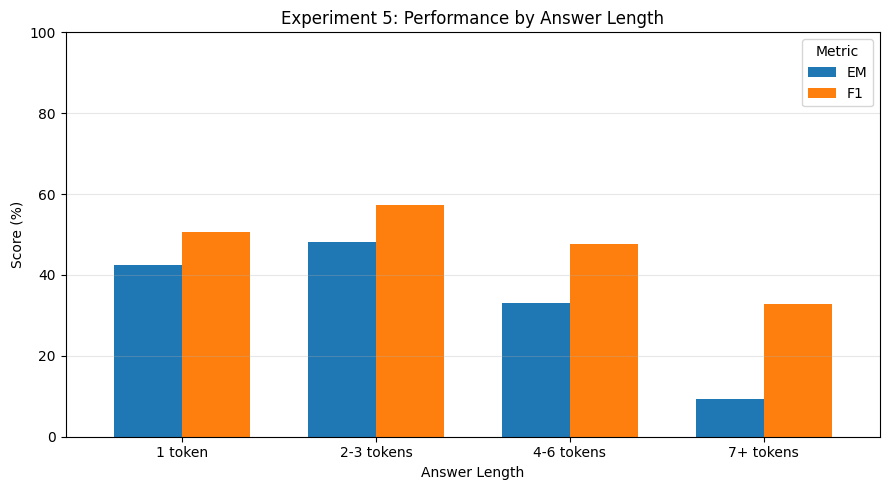

In [111]:
plot_df = exp5_results.set_index(
    "length_group"
)[["EM", "F1"]]

plot_df.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

plt.title("Experiment 5: Performance by Answer Length")
plt.xlabel("Answer Length")
plt.ylabel("Score (%)")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Metric")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

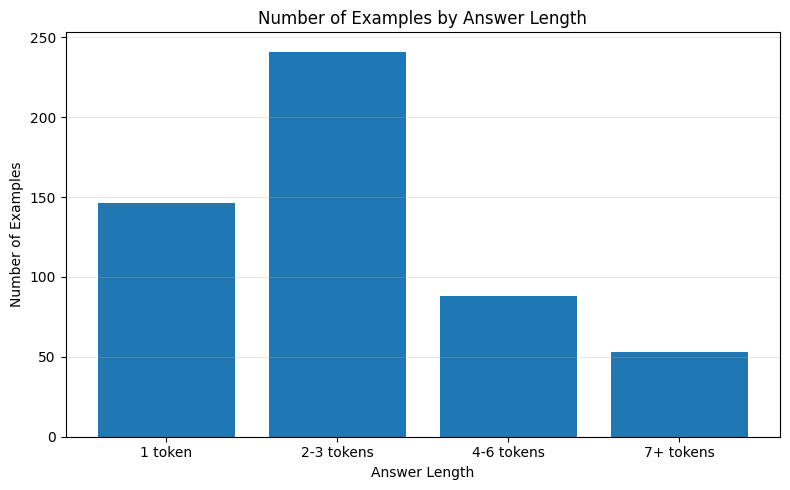

In [112]:
plt.figure(figsize=(8, 5))

counts = exp5_df["length_group"].value_counts()
counts = counts.reindex(group_order, fill_value=0)

plt.bar(counts.index, counts.values)

plt.title("Number of Examples by Answer Length")
plt.xlabel("Answer Length")
plt.ylabel("Number of Examples")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [113]:
exp5_df["prediction_length"] = exp5_df[
    "prediction"
].apply(count_answer_tokens)

exp5_df["length_difference"] = (
    exp5_df["prediction_length"]
    - exp5_df["answer_length"]
)

exp5_df["prediction_length_status"] = np.select(
    [
        exp5_df["length_difference"] < 0,
        exp5_df["length_difference"] == 0,
        exp5_df["length_difference"] > 0
    ],
    [
        "Prediction shorter",
        "Same length",
        "Prediction longer"
    ],
    default="Unknown"
)

length_comparison = (
    exp5_df
    .groupby("prediction_length_status")
    .size()
    .reset_index(name="Num_Examples")
)

display(length_comparison)

,prediction_length_status,Num_Examples
0,Prediction longer,170
1,Prediction shorter,151
2,Same length,207


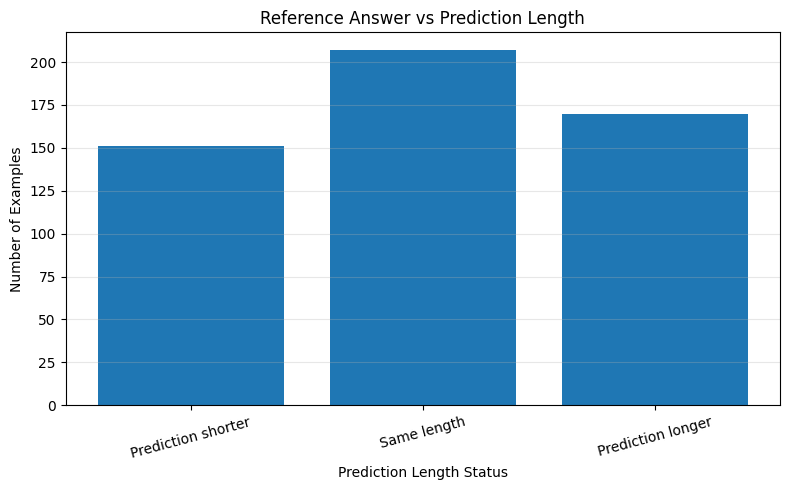

In [114]:
status_order = [
    "Prediction shorter",
    "Same length",
    "Prediction longer"
]

length_counts = (
    exp5_df["prediction_length_status"]
    .value_counts()
    .reindex(status_order, fill_value=0)
)

plt.figure(figsize=(8, 5))

plt.bar(
    length_counts.index,
    length_counts.values
)

plt.title("Reference Answer vs Prediction Length")
plt.xlabel("Prediction Length Status")
plt.ylabel("Number of Examples")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [115]:
display(
    exp5_df[
        [
            "question",
            "reference_answer",
            "prediction",
            "answer_length",
            "prediction_length",
            "length_difference",
            "EM",
            "F1"
        ]
    ].head(15)
)

,question,reference_answer,prediction,answer_length,prediction_length,length_difference,EM,F1
0,What does increased oxygen concentrations in t...,carbon monoxide,carbon monoxide from the heme group of hemoglobin,2,8,6,0.0,0.444444
1,Does the new deal include Video on demand and ...,no,additional Video On Demand and High Definition...,1,8,7,0.0,0.000000
2,In which year did Genghis Khan's grandson inva...,1237,1237,1,1,0,1.0,1.000000
3,Where is the Hyde Park Day School located?,the University of Chicago campus,"the Hyde Park Day School, a school for student...",5,12,7,0.0,0.000000
4,What does the WG I Summary for Policymakers re...,substantially increasing the atmospheric conce...,executive,5,1,-4,0.0,0.000000
5,For how many years was evidence shown that hum...,"11,000 years","11,000 years",3,3,0,1.0,1.000000
6,Who lost to the Broncos in the divisional round?,Pittsburgh Steelers,Pittsburgh Steelers,2,2,0,1.0,1.000000
7,Who was hired to be the deputy director of the...,Joseph Shea,Joseph Shea,2,2,0,1.0,1.000000
8,What register did Chris Keates think that some...,the sex offenders register,sex offenders register,4,3,-1,1.0,1.000000
9,What did Luther say would allow the Jews to stay?,that they convert,Eisleben,3,1,-2,0.0,0.000000


In [116]:
wrong_predictions = exp5_df[
    exp5_df["EM"] == 0
].sort_values(
    by="answer_length",
    ascending=False
)

display(
    wrong_predictions[
        [
            "question",
            "reference_answer",
            "prediction",
            "answer_length",
            "prediction_length",
            "F1"
        ]
    ].head(15)
)

,question,reference_answer,prediction,answer_length,prediction_length,F1
453,At what time is the Harvard-Yale rivalry set a...,every two years when the Harvard and Yale Trac...,two years,25,2,0.800000
501,Funding limitations allowed CSNET to be what,"role in spreading awareness of, and access to,...",1981,24,1,0.000000
386,Was the Use of the DATANET 1 name correct,use of the name was incorrect all these servic...,Telepad,24,1,0.000000
441,How did the settlers protect their interests?,"banned the growing of coffee, introduced a hut...","80,000",23,2,0.000000
324,What were X.25 and Frame relay used for,Frame Relay was used to interconnect LANs acro...,interconnect LANs,22,2,0.173913
281,Why is the public library known as a people's ...,"it is open to all irrespective of age, literac...",Kenya National Library Service,21,4,0.000000
337,What is Christian Perfection?,"a genuine love of God with heart, soul, mind, ...",evil,20,1,0.000000
190,"Besides drugs, what else do specialty pharmaci...","lab monitoring, adherence counseling, and assi...","lab monitoring, adherence counseling",18,4,0.571429
466,DEC originally had 3 layers but evolved into h...,"Initially built with three layers, it later (1...",seven-layer OSI-compliant networking protocol,17,6,0.444444
283,What was the trend of female student populatio...,the proportion of female undergraduates steadi...,four,17,1,0.000000
